In [1]:
import os
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2

import time

############################################################
# 1. Dataset Class (수정됨)
############################################################
class SegDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root = root_dir
        self.transform = transform

        self.img_dir = os.path.join(root_dir, "RGB")
        self.mask_dir = os.path.join(root_dir, "Label")

        self.img_list = sorted(os.listdir(self.img_dir))
        self.mask_list = sorted(os.listdir(self.mask_dir))

        # 파일 개수 확인
        assert len(self.img_list) == len(self.mask_list), "이미지/마스크 개수가 다릅니다."

    def __len__(self):
        return len(self.img_list)

    def __getitem__(self, idx):
        # 오류 로그에 있던 self.images -> self.img_list로 명확히 사용
        img_path = os.path.join(self.img_dir, self.img_list[idx])
        mask_path = os.path.join(self.mask_dir, self.mask_list[idx])

        # 이미지 로드 (BGR -> RGB)
        image = cv2.imread(img_path)
        if image is None:
            raise FileNotFoundError(f"이미지를 찾을 수 없습니다: {img_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # 마스크 로드
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is None:
            raise FileNotFoundError(f"마스크를 찾을 수 없습니다: {mask_path}")

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"]

        return image, mask.long()

# 학습용 변환 (랜덤 증강 제거, 필수 전처리만 유지)
train_transform = A.Compose([
    # [필수] 모델 입력 크기에 맞춰 리사이즈 (RandomResizedCrop 대신 사용)
    A.Resize(height=256, width=256),

    # [필수] ResNet 등 Pre-trained 모델 학습을 위한 정규화
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),

    # [필수] PyTorch 텐서로 변환
    ToTensorV2()
])

# 검증용 변환 (학습용과 동일)
val_transform = A.Compose([
    A.Resize(height=256, width=256),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

In [27]:

# Model
NUM_CLASSES = 13

class khaha(nn.Module):
  def __init__(self, num_classes):
    super(khaha, self).__init__()
    self.leaky = nn.LeakyReLU(0.1)

  # conv1
    self.conv1_1 = nn.Conv2d(3,64,3,padding=1)
    self.conv1_2 = nn.Conv2d(64,64,3, padding=1)
    self.pool1 = nn.MaxPool2d(2, stride=2, ceil_mode=True)


  # conv2
    self.conv2_1 = nn.Conv2d(64,128,3,padding=1)
    self.conv2_2 = nn.Conv2d(128,128,3, padding=1)
    self.pool2 = nn.MaxPool2d(2, stride=2, ceil_mode=True)

  # conv3
    self.conv3_1 = nn.Conv2d(128,256,3,padding=1)
    self.conv3_2 = nn.Conv2d(256,256,3, padding=1)
    self.pool3 = nn.MaxPool2d(2, stride=2, ceil_mode=True)

  # conv4
    self.conv4_1 = nn.Conv2d(256,512,3,padding=1)
    self.conv4_2 = nn.Conv2d(512,512,3, padding=1)
    self.pool4 = nn.MaxPool2d(2, stride=2, ceil_mode=True)

  # conv5
    self.conv5_1 = nn.Conv2d(512,1024,3,padding=1)
    self.conv5_2 = nn.Conv2d(1024,1024,3, padding=1)
    self.pool5 = nn.MaxPool2d(2, stride=2, ceil_mode=True)

  # conv6
    self.conv6 = nn.Conv2d(1024,1024,3,padding=1)
    self.conv6_1 = nn.Conv2d(1024,1024,3, padding=1)
    self.conv6_2 = nn.Conv2d(1024,1024,3, padding=1)
    self.pool6 = nn.MaxPool2d(2, stride=2, ceil_mode=True)



  #==========Decoder=======================
  # [Up 4] 1024 -> 512 로 줄이면서 크기는 2배 키움
    self.upconv5 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
    self.dec5_1 = nn.Conv2d(1536, 512, 3, padding=1)
    self.dec5_2 = nn.Conv2d(512, 512, 3, padding=1)

  # 512 -> 256
    self.upconv4 = nn.ConvTranspose2d(512, 256,2,stride=2)
    self.dec4_1 = nn.Conv2d(768, 256, 3, padding=1)
    self.dec4_2 = nn.Conv2d(256, 256, 3, padding=1)

  # 256 -> 128
    self.upconv3 = nn.ConvTranspose2d(256, 128,2,stride=2)
    self.dec3_1 = nn.Conv2d(384, 128, 3, padding=1)
    self.dec3_2 = nn.Conv2d(128, 128, 3, padding=1)

  # 128 -> 64
    self.upconv2 = nn.ConvTranspose2d(128, 64,2,stride=2)
    self.dec2_1 = nn.Conv2d(192, 64, 3, padding=1)
    self.dec2_2 = nn.Conv2d(64, 64, 3, padding=1)

  # 64 -> 32
    self.upconv1 = nn.ConvTranspose2d(64,32, 2,stride = 2)
    self.dec1_1 = nn.Conv2d(96, 32, 3, padding=1)
    self.dec1_2 = nn.Conv2d(32, 32, 3, padding=1)

  # final
    self.final_conv = nn.Conv2d(32, num_classes, kernel_size=1)

  def forward(self,x):
    # Encoding
    #Block1
    x= self.leaky(self.conv1_1(x))
    x= self.leaky(self.conv1_2(x))
    skip1 = x
    x= self.pool1(x)

    # Block2
    x = self.leaky(self.conv2_1(x))
    x = self.leaky(self.conv2_2(x))
    skip2 = x
    x=self.pool2(x)


    # Block3
    x = self.leaky(self.conv3_1(x))
    x = self.leaky(self.conv3_2(x))
    skip3 = x
    x = self.pool3(x)

    # Block4
    x = self.leaky(self.conv4_1(x))
    x = self.leaky(self.conv4_2(x))
    skip4 = x
    x = self.pool4(x)

    # Block5
    x = self.leaky(self.conv5_1(x))
    x = self.leaky(self.conv5_2(x))
    skip5 = x
    x = self.pool5(x)

    # Block6
    x = self.leaky(self.conv6(x))
    x = self.leaky(self.conv6_1(x))
    x = self.leaky(self.conv6_2(x))


    # ===============Decoder===================

    # <5>
    x = self.upconv5(x)
    x = torch.cat((x,skip5),dim=1)
    x = self.leaky(self.dec5_1(x))
    x = self.leaky(self.dec5_2(x))

    # <4>
    x = self.upconv4(x)
    x = torch.cat((x,skip4),dim=1)
    x = self.leaky(self.dec4_1(x))
    x = self.leaky(self.dec4_2(x))

    # <3>
    x = self.upconv3(x)
    x = torch.cat((x,skip3),dim=1)
    x = self.leaky(self.dec3_1(x))
    x = self.leaky(self.dec3_2(x))

    # <2>
    x = self.upconv2(x)
    x = torch.cat((x,skip2),dim=1)
    x = self.leaky(self.dec2_1(x))
    x = self.leaky(self.dec2_2(x))

    # <1>
    x = self.upconv1(x)
    x = torch.cat((x,skip1),dim=1)
    x = self.leaky(self.dec1_1(x))
    x = self.leaky(self.dec1_2(x))

    # <final>
    out = self.final_conv(x)

    return out


In [ ]:
############################################################
# 4. DataLoader & Training (클래스명 수정됨)
############################################################
# [수정] SegmentationDataset -> SegDataset으로 변경
train_dataset = SegDataset(
    "/content/drive/MyDrive/dataset/2D Segmentation/Training",
    transform=train_transform
)
val_dataset = SegDataset(
    "/content/drive/MyDrive/dataset/2D Segmentation/Validation",
    transform=val_transform
)

if torch.cuda.is_available():
    device = "cuda"
    print("✅ GPU(CUDA)를 사용합니다.")
    print(f"   - GPU 이름: {torch.cuda.get_device_name(0)}")
else:
    device = "cpu"
    print("❌ GPU를 사용할 수 없습니다. CPU로 실행됩니다.")

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=2) # 코랩 등에서는 worker 2 추천
val_loader = DataLoader(val_dataset, batch_size=2, shuffle=False, num_workers=2)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = khaha(num_classes=NUM_CLASSES).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=255)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

EPOCHS = 15

print("Start Training...")
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for imgs, masks in train_loader:
        imgs = imgs.to(device)
        masks = masks.to(device)

        out = model(imgs)

        loss = criterion(out,masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"[Epoch {epoch+1}] Train Loss: {total_loss/len(train_loader):.4f}")

✅ GPU(CUDA)를 사용합니다.
   - GPU 이름: Tesla T4
Start Training...


--------------------------------------------------
🎲 선택된 마스크: 03_00_150.png
📸 매칭된 이미지: 03_00_150.png
--------------------------------------------------


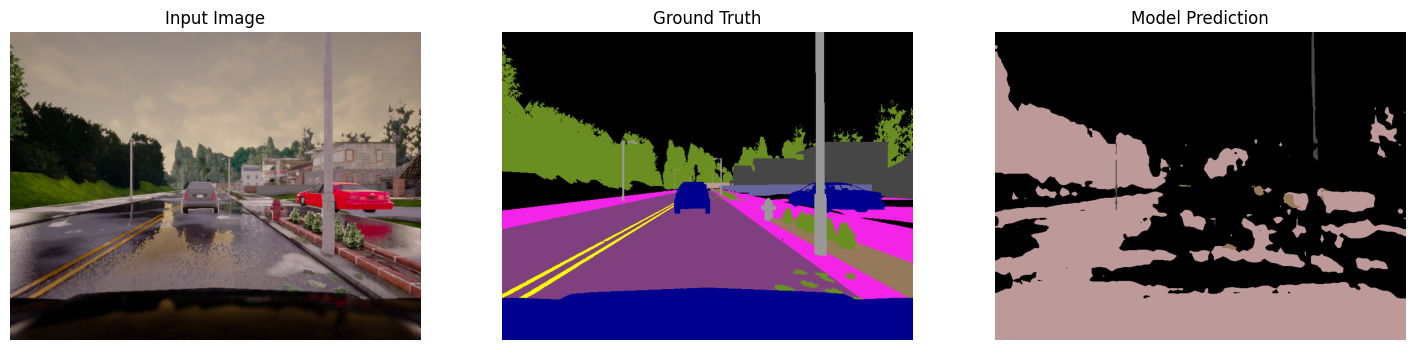

ℹ️ 포함된 클래스 (GT): [ 0  1  2  3  5  6  7  8  9 10 11]
ℹ️ 예측된 클래스 (Pred): [0 1 2 3]


In [42]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torchvision import transforms

# ==================================================================
# 1. 경로 설정 (⚠️ 본인 경로 확인 필수)
# ==================================================================
MASK_DIR = "/content/drive/MyDrive/dataset/2D Segmentation/Validation/Label"
IMAGE_DIR = "/content/drive/MyDrive/dataset/2D Segmentation/Validation/RGB"

# ==================================================================
# 2. 팔레트 정의
# ==================================================================
PALETTE = np.array([
    [0, 0, 0],          # 0 None
    [70, 70, 70],       # 1 Buildings
    [190, 153, 153],    # 2 Fences
    [150, 120, 90],     # 3 Other
    [220, 20, 60],      # 4 Pedestrians
    [153, 153, 153],    # 5 Poles
    [255, 255, 0],      # 6 RoadLines
    [128, 64, 128],     # 7 Roads
    [244, 35, 232],     # 8 Sidewalks
    [107, 142, 35],     # 9 Vegetation
    [0, 0, 142],        # 10 Vehicles
    [102, 102, 156],    # 11 Walls
    [220, 220, 0],      # 12 TrafficSigns
], dtype=np.uint8)

def colorize_mask(mask):
    mask_copy = mask.copy()
    mask_copy[mask_copy >= len(PALETTE)] = 0
    return PALETTE[mask_copy]

# ==================================================================
# 3. [핵심 수정] 파일명 매칭 함수
# ==================================================================
def find_image_file(mask_filename, image_dir):
    """
    마스크 파일명을 이용해 원본 이미지 경로를 찾습니다.
    _mask, _label 등의 접미사를 제거하며 매칭을 시도합니다.
    """
    # 확장자 제거 (예: file_mask.png -> file_mask)
    base_name = os.path.splitext(mask_filename)[0]

    # 제거할 접미사 목록 (본인 데이터셋에 맞춰 추가 가능)
    suffixes_to_remove = ["_mask", "_label", "_gt", "_L", "Label", "Mask"]

    # 1. 접미사 제거 시도
    clean_name = base_name
    for suffix in suffixes_to_remove:
        clean_name = clean_name.replace(suffix, "") # 접미사 제거

    clean_name = clean_name.strip() # 앞뒤 공백 제거

    # 2. 가능한 이미지 확장자 목록
    valid_exts = [".png", ".jpg", ".jpeg", ".bmp"]

    # 3. 파일 찾기
    # (A) 원본 이름 그대로 찾아보기
    for ext in valid_exts:
        candidate = os.path.join(image_dir, base_name + ext)
        if os.path.exists(candidate):
            return candidate

    # (B) 접미사를 뗀 이름으로 찾아보기 (가장 유력)
    for ext in valid_exts:
        candidate = os.path.join(image_dir, clean_name + ext)
        if os.path.exists(candidate):
            return candidate

    return None

# ==================================================================
# 4. 시각화 실행 함수
# ==================================================================
def show_random_prediction(model, device):
    if not os.path.exists(MASK_DIR) or not os.path.exists(IMAGE_DIR):
        print("❌ 오류: 폴더 경로를 확인해주세요.")
        return

    files = os.listdir(MASK_DIR)
    mask_files = [f for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

    if not mask_files:
        print("❌ 마스크 폴더에 파일이 없습니다.")
        return

    # 랜덤 선택
    chosen_mask_file = random.choice(mask_files)

    # 🔍 짝이 맞는 이미지 찾기 (수정된 함수 사용)
    img_path = find_image_file(chosen_mask_file, IMAGE_DIR)
    mask_path = os.path.join(MASK_DIR, chosen_mask_file)

    print(f"--------------------------------------------------")
    print(f"🎲 선택된 마스크: {chosen_mask_file}")

    if img_path is None:
        print(f"❌ 원본 이미지를 찾을 수 없습니다.")
        print(f"   (찾으려던 예상 이름: {os.path.splitext(chosen_mask_file)[0]} 등)")
        return

    print(f"📸 매칭된 이미지: {os.path.basename(img_path)}")
    print(f"--------------------------------------------------")

    # 데이터 로드 및 전처리
    img_pil = Image.open(img_path).convert("RGB")
    mask_np = np.array(Image.open(mask_path))

    if mask_np.ndim == 3:
        mask_np = mask_np[:, :, 0]

    # 모델 예측
    model.eval()
    model.to(device)

    preprocess = transforms.Compose([
        transforms.Resize((mask_np.shape[0], mask_np.shape[1])),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    input_tensor = preprocess(img_pil).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_tensor)
        pred_tensor = output['out'].argmax(dim=1).squeeze(0)
        pred_np = pred_tensor.cpu().numpy().astype(np.uint8)

    # 시각화
    img_vis = np.array(img_pil.resize((mask_np.shape[1], mask_np.shape[0])))
    gt_color = colorize_mask(mask_np)
    pred_color = colorize_mask(pred_np)

    plt.figure(figsize=(18, 6))
    plt.subplot(1, 3, 1); plt.title("Input Image"); plt.imshow(img_vis); plt.axis('off')
    plt.subplot(1, 3, 2); plt.title("Ground Truth"); plt.imshow(gt_color); plt.axis('off')
    plt.subplot(1, 3, 3); plt.title("Model Prediction"); plt.imshow(pred_color); plt.axis('off')
    plt.show()

    print(f"ℹ️ 포함된 클래스 (GT): {np.unique(mask_np)}")
    print(f"ℹ️ 예측된 클래스 (Pred): {np.unique(pred_np)}")

# 실행
device = "cuda" if torch.cuda.is_available() else "cpu"
show_random_prediction(model, device)

In [37]:
import torch
import numpy as np
from tqdm import tqdm

# 1. 클래스 이름 정의 (결과를 보기 좋게 출력하기 위함)
CLASS_NAMES = [
    "None (Background)", # 0
    "Buildings",         # 1
    "Fences",            # 2
    "Other",             # 3
    "Pedestrians",       # 4
    "Poles",             # 5
    "RoadLines",         # 6
    "Roads",             # 7
    "Sidewalks",         # 8
    "Vegetation",        # 9
    "Vehicles",          # 10
    "Walls",             # 11
    "TrafficSigns"       # 12
]

def calculate_class_iou(model, dataloader, device, num_classes=13):
    model.eval()
    model.to(device)

    # 전체 데이터셋에 대한 교집합(Intersection)과 합집합(Union)을 저장할 리스트
    total_intersection = torch.zeros(num_classes).to(device)
    total_union = torch.zeros(num_classes).to(device)

    print("📊 전체 검증 데이터셋에 대해 IoU 계산 중...")

    with torch.no_grad():
        # tqdm으로 진행상황 표시
        for imgs, masks in tqdm(dataloader, desc="Evaluating"):
            imgs = imgs.to(device)
            masks = masks.to(device)

            # 1. 모델 예측
            out = model(imgs)
            preds = torch.argmax(out['out'], dim=1) # (B, H, W)

            # 2. 배치 내의 각 클래스별 IoU 요소 계산
            for cls in range(num_classes):
                # 현재 클래스에 해당하는 픽셀 마스크 생성
                pred_inds = (preds == cls)
                target_inds = (masks == cls)

                # 교집합 (AND 연산): 예측과 정답이 모두 해당 클래스인 픽셀 수
                intersection = (pred_inds & target_inds).long().sum()

                # 합집합 (OR 연산): 예측이나 정답 중 하나라도 해당 클래스인 픽셀 수
                union = (pred_inds | target_inds).long().sum()

                # 누적
                total_intersection[cls] += intersection
                total_union[cls] += union

    # 3. 최종 IoU 계산
    # 합집합이 0인 경우(해당 클래스가 아예 등장 안 함) NaN 방지를 위해 1e-6 더함
    iou_per_class = total_intersection / (total_union + 1e-6)

    # 텐서를 리스트로 변환
    iou_per_class = iou_per_class.cpu().numpy()

    return iou_per_class

# ====================================================
# 실행 및 결과 출력
# ====================================================

# 설정
NUM_CLASSES = 13
device = "cuda" if torch.cuda.is_available() else "cpu"

# 함수 실행
ious = calculate_class_iou(model, val_loader, device, NUM_CLASSES)

# 결과 출력
print("\n" + "="*40)
print(f"{'Class Name':<20} | {'IoU Score':<10}")
print("-" * 40)

valid_ious = []
for idx, iou in enumerate(ious):
    class_name = CLASS_NAMES[idx] if idx < len(CLASS_NAMES) else f"Class {idx}"

    # 합집합이 거의 0이라 IoU가 0인 경우 제외하고 평균 낼지 결정
    # 여기서는 단순히 출력만 함
    print(f"{class_name:<20} | {iou:.4f}")

    # 평균 계산을 위해 유효한 클래스(데이터에 존재하는 클래스)만 모음
    # (완전 0.0000인 경우 데이터에 없었거나 모델이 아예 못 맞춘 경우임)
    valid_ious.append(iou)

print("="*40)
mIoU = np.mean(valid_ious)
print(f"🏆 Mean IoU (mIoU)    | {mIoU:.4f}")
print("="*40)

📊 전체 검증 데이터셋에 대해 IoU 계산 중...


Evaluating: 100%|██████████| 500/500 [12:29<00:00,  1.50s/it]


Class Name           | IoU Score 
----------------------------------------
None (Background)    | 0.8027
Buildings            | 0.0913
Fences               | 0.8166
Other                | 0.1370
Pedestrians          | 0.0000
Poles                | 0.0000
RoadLines            | 0.0000
Roads                | 0.0000
Sidewalks            | 0.0000
Vegetation           | 0.0000
Vehicles             | 0.0000
Walls                | 0.0000
TrafficSigns         | 0.0000
🏆 Mean IoU (mIoU)    | 0.1421
